In [1]:
import sys
from pathlib import Path
import json
import numpy as np
import faiss
import matplotlib.pyplot as plt

from sentence_transformers import SentenceTransformer

sys.path.append("..")

from src.data import load_config
from src.features import chunk_text
from src.models import search_similar_chunks

c:\Users\pawel\Documents\GitHub\rag-AUD-project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


#### 1. Loading configuration and results

In [2]:
cfg = load_config("../configs/config.yaml")

variant = cfg["data"]["variant"]
model_dir = Path("../models") / variant

with open(model_dir / "chunks.json", "r", encoding="utf-8") as f:
    chunks = json.load(f)

index = faiss.read_index(str(model_dir / "faiss.index"))

print("Number of chunks:", len(chunks))
print("FAISS index size:", index.ntotal)

Number of chunks: 134
FAISS index size: 134


#### 2. Basic tests

In [3]:
assert len(chunks) > 0
assert index.ntotal == len(chunks)

for chunk in chunks:
    assert chunk["text"].strip() != ""
    assert "source" in chunk
    assert "chapter" in chunk
    assert "section" in chunk

print("All basic checks passed!")

All basic checks passed!


#### 3. Checking embeddings

In [4]:
vectors = index.reconstruct_n(0, index.ntotal)

print("Embedding shape:", vectors.shape)
print("First vector norm:", np.linalg.norm(vectors[0]))

assert np.allclose(
    np.linalg.norm(vectors, axis=1),
    1.0,
    atol=1e-4
)

print("Embedding checks passed!")

Embedding shape: (134, 384)
First vector norm: 1.0
Embedding checks passed!


#### 4. Testing search

In [5]:
model = SentenceTransformer(
    cfg["embeddings"]["model_name"]
)

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 5806.32it/s]


In [6]:
def test_retrieval(query, top_k=5):

    results = search_similar_chunks(
        query=query,
        index=index,
        chunks=chunks,
        model=model,
        top_k=top_k
    )

    print("QUERY:", query)
    print("=" * 80)

    for i, result in enumerate(results, 1):
        chunk = result["chunk"]

        print(f"\nRESULT {i}")
        print(f"Score: {result['score']:.4f}")
        print(f"Chapter: {chunk['chapter']}")
        print(f"Section: {chunk['section']}")
        print(f"Pages: {chunk['pdf_page_start']} - {chunk['pdf_page_end']}")
        print(f"Text: {chunk['text'][:700]}")
        print("-" * 80)

In [7]:
test_retrieval(
    "What are the main concepts discussed in this chapter?"
)

test_retrieval(
    "What is the meaning of the key terms introduced in this section?"
)

test_retrieval(
    "What are the main differences between the concepts discussed?"
)

QUERY: What are the main concepts discussed in this chapter?

RESULT 1
Score: 0.3304
Chapter: 3
Section: 3.1 The Division of Powers
Pages: 32 - 33
Text: In seeking not to replay the problems that plagued the young country under the Articles of Confederation, the Constitution’s framers granted Congress specific powers that ensured its authority over national and foreign affairs. To provide for the general welfare of the populace, it can tax, borrow money, regulate interstate and foreign commerce, and protect property rights, for example. To provide for the common defense of the people, the federal government can raise and support armies and declare war. Furthermore, national integration and unity are fostered with the government’s powers over the coining of money, naturalization, postal services, and other responsibilities. The last clause of
--------------------------------------------------------------------------------

RESULT 2
Score: 0.3090
Chapter: 2
Section: 2.3 The Development o

#### 5. Visualization of chunk length distribution

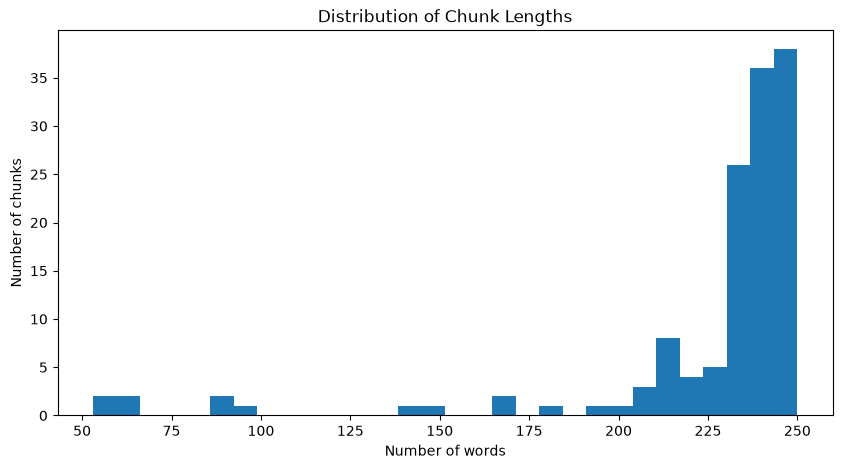

Average chunk length: 225.2910447761194
Minimum chunk length: 53
Maximum chunk length: 250


In [8]:
chunk_lengths = [
    len(chunk["text"].split())
    for chunk in chunks
]

plt.figure(figsize=(10, 5))
plt.hist(chunk_lengths, bins=30)
plt.xlabel("Number of words")
plt.ylabel("Number of chunks")
plt.title("Distribution of Chunk Lengths")
plt.show()

print("Average chunk length:", np.mean(chunk_lengths))
print("Minimum chunk length:", np.min(chunk_lengths))
print("Maximum chunk length:", np.max(chunk_lengths))